In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten, MaxPooling2D, Dropout

from tensorflow.keras.utils import to_categorical

In [36]:
df = pd.read_csv('mnist_train.csv')
df_test = pd.read_csv('mnist_test.csv')

In [37]:
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [38]:
df.columns

Index(['label', '1x1', '1x2', '1x3', '1x4', '1x5', '1x6', '1x7', '1x8', '1x9',
       ...
       '28x19', '28x20', '28x21', '28x22', '28x23', '28x24', '28x25', '28x26',
       '28x27', '28x28'],
      dtype='object', length=785)

In [39]:
df.isnull().sum()

,0
label,0
1x1,0
1x2,0
1x3,0
1x4,0
...,...
28x24,0
28x25,0
28x26,0
28x27,0


In [48]:
X_train = df.drop('label', axis=1)
y_train = df['label']
X_test = df_test.drop('label', axis=1)
y_test = df_test['label']

In [47]:
X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255

In [49]:
X_train_img = X_train.values.reshape(-1, 28, 28)
X_test_img = X_test.values.reshape(-1, 28, 28)

In [50]:
y_train_cat = to_categorical(y_train)
y_test_cat = to_categorical(y_test)

In [53]:
perceptron = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(10, activation='softmax')
])

In [54]:
perceptron.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

In [57]:
history_perceptron = perceptron.fit(X_train_img, y_train_cat, epochs=5, batch_size=32, validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8422 - loss: 310.8706 - val_accuracy: 0.8631 - val_loss: 255.1781
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8674 - loss: 260.8734 - val_accuracy: 0.8791 - val_loss: 242.1898
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8737 - loss: 250.1114 - val_accuracy: 0.8808 - val_loss: 234.4930
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8756 - loss: 248.2467 - val_accuracy: 0.8953 - val_loss: 211.9457
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8780 - loss: 241.6743 - val_accuracy: 0.9081 - val_loss: 203.1587


In [58]:
acc_perceptron = perceptron.evaluate(X_test_img, y_test_cat)[1]

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9081 - loss: 203.1587


In [59]:
acc_perceptron

0.9081000089645386

#ANN


In [61]:
ann = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax'),
])

In [62]:
ann.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [63]:
history_ann = ann.fit(X_train_img, y_train_cat, epochs=5, batch_size=32, validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8721 - loss: 1.5781 - val_accuracy: 0.9195 - val_loss: 0.3973
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9318 - loss: 0.2813 - val_accuracy: 0.9284 - val_loss: 0.2983
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9465 - loss: 0.1988 - val_accuracy: 0.9444 - val_loss: 0.2185
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9555 - loss: 0.1626 - val_accuracy: 0.9563 - val_loss: 0.1701
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9589 - loss: 0.1463 - val_accuracy: 0.9589 - val_loss: 0.1512


In [64]:
acc_ann = ann.evaluate(X_test_img, y_test_cat)[1]

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9589 - loss: 0.1512


#CNN

In [66]:
X_train_cnn = X_train.values.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.values.reshape(-1, 28, 28, 1)

In [68]:
cnn = Sequential([
    Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax'),
])

In [69]:
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [70]:
history_cnn = cnn.fit(X_train_cnn, y_train_cat, epochs=5, batch_size=32, validation_data=(X_test_cnn, y_test_cat), verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 38s 20ms/step - accuracy: 0.8763 - loss: 0.5160 - val_accuracy: 0.9767 - val_loss: 0.0798
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 36s 19ms/step - accuracy: 0.9604 - loss: 0.1399 - val_accuracy: 0.9833 - val_loss: 0.0557
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 36s 19ms/step - accuracy: 0.9693 - loss: 0.1090 - val_accuracy: 0.9835 - val_loss: 0.0565
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 36s 19ms/step - accuracy: 0.9734 - loss: 0.0922 - val_accuracy: 0.9869 - val_loss: 0.0412
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 40s 19ms/step - accuracy: 0.9764 - loss: 0.0813 - val_accuracy: 0.9881 - val_loss: 0.0437


In [71]:
acc_cnn = cnn.evaluate(X_test_cnn, y_test_cat)[1]

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9881 - loss: 0.0437


##Visualisation


In [72]:
def plot_training(history, title):
  plt.figure(figsize=(12,4))
  plt.subplot(1, 2, 1)
  plt.plot(history.history['accuracy'], label='Training Accuracy')
  plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
  plt.xlabel('Epochs')
  plt.ylabel('Accuracy')
  plt.title(f'{title} - Accuracy')
  plt.legend()

  plt.subplot(1, 2, 2)
  plt.plot(history.history['loss'], label='Training Loss')
  plt.plot(history.history['val_loss'], label='Validation Loss')
  plt.xlabel('Epochs')
  plt.ylabel('Loss')
  plt.title(f'{title} - Loss')
  plt.legend()

  plt.show()

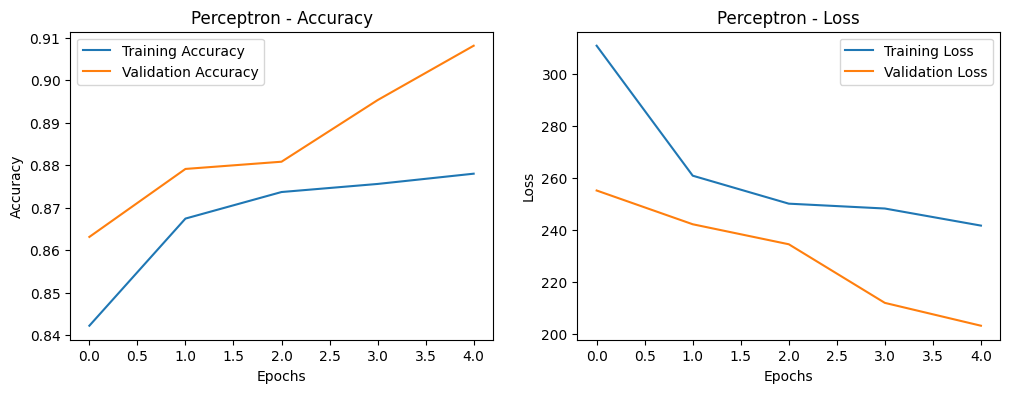

In [73]:
plot_training(history_perceptron, 'Perceptron')

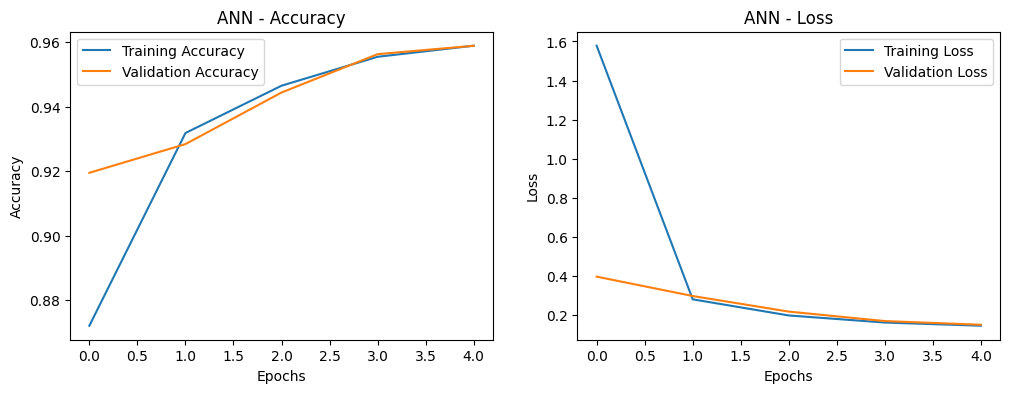

In [74]:
plot_training(history_ann, 'ANN')

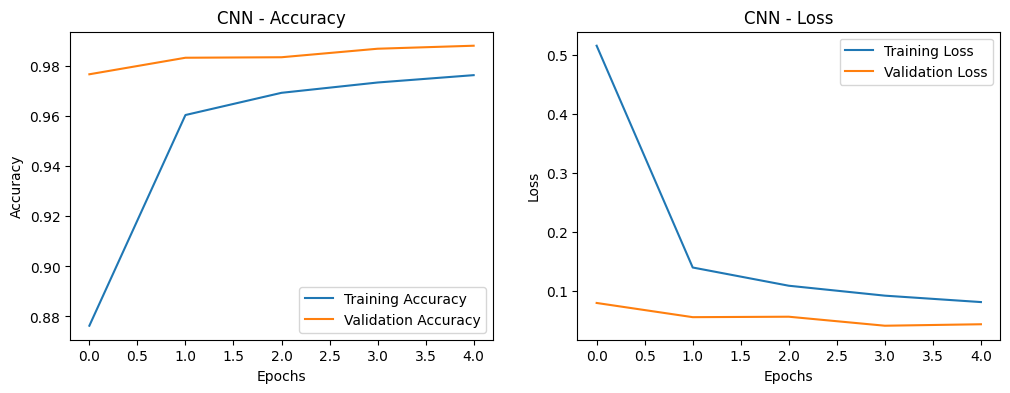

In [75]:
plot_training(history_cnn, 'CNN')

## Model Comparison

        Model  Validation Accuracy
0  Perceptron               0.9081
1         ANN               0.9589
2         CNN               0.9881


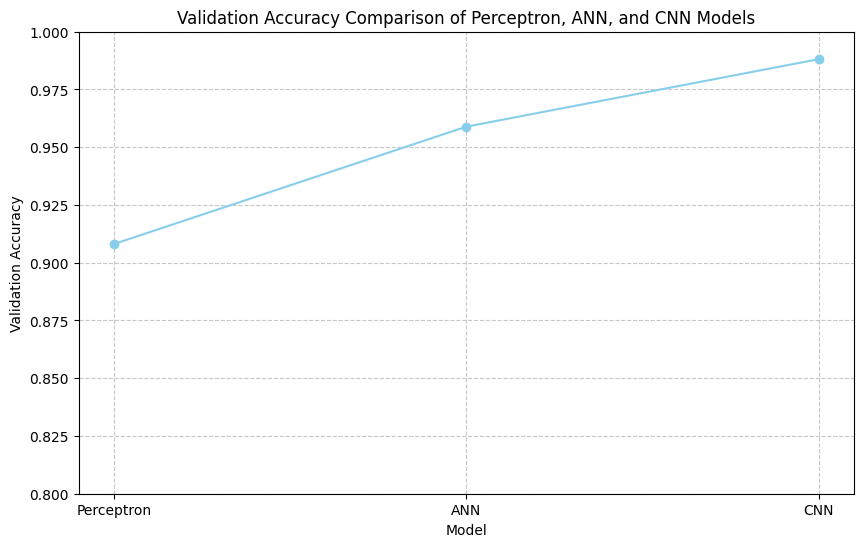

In [77]:
model_accuracies = pd.DataFrame({
    'Model': ['Perceptron', 'ANN', 'CNN'],
    'Validation Accuracy': [acc_perceptron, acc_ann, acc_cnn]
})

print(model_accuracies)

plt.figure(figsize=(10, 6))
plt.plot(model_accuracies['Model'], model_accuracies['Validation Accuracy'], marker='o', linestyle='-', color='skyblue')
plt.title('Validation Accuracy Comparison of Perceptron, ANN, and CNN Models')
plt.xlabel('Model')
plt.ylabel('Validation Accuracy')
plt.ylim(0.8, 1.0) # Set y-axis limits to better show differences
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

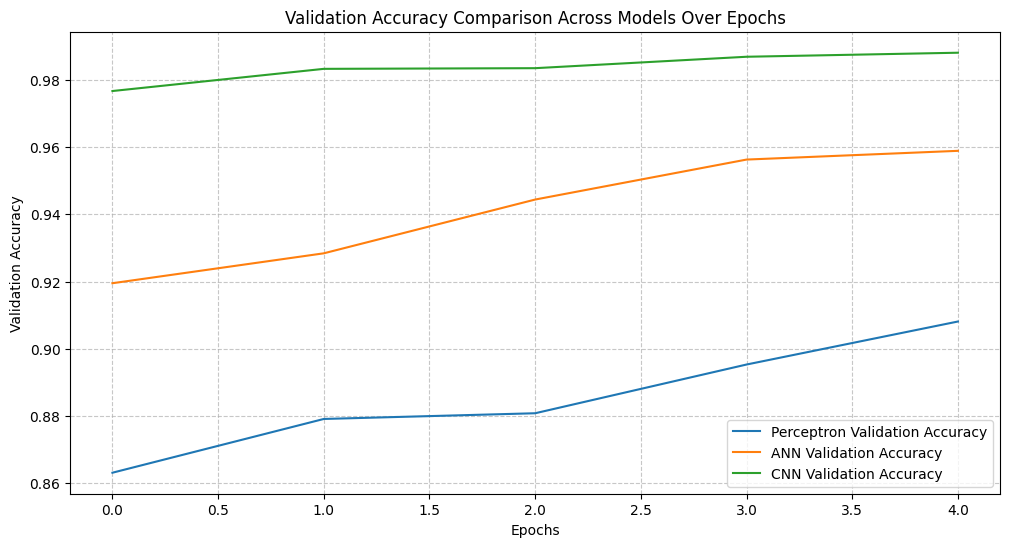

In [81]:
plt.figure(figsize=(12, 6))

plt.plot(history_perceptron.history['val_accuracy'], label='Perceptron Validation Accuracy')
plt.plot(history_ann.history['val_accuracy'], label='ANN Validation Accuracy')
plt.plot(history_cnn.history['val_accuracy'], label='CNN Validation Accuracy')

plt.title('Validation Accuracy Comparison Across Models Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [83]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
  idxs = np.random.choice(len(X), n, replace=False)
  plt.figure(figsize=(15, 6))
  for i, idx in enumerate(idxs):
    plt.subplot(2, n, i+1)
    plt.imshow(X[idx].reshape (28, 28), cmap="gray")
    plt.axis("off")
    plt.title(f"True: {y_true [idx]}")
    preds = [np.argmax(model.predict(X_cnn [idx].reshape(1, 28, 28, 1) if
    name == "CNN" else X[idx].reshape(1, 28, 28)))

             for model, name in zip(models, model_names)]
    plt.subplot(2, n, n+i+1)
    plt.axis("off")
    plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
  plt.tight_layout()
  plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


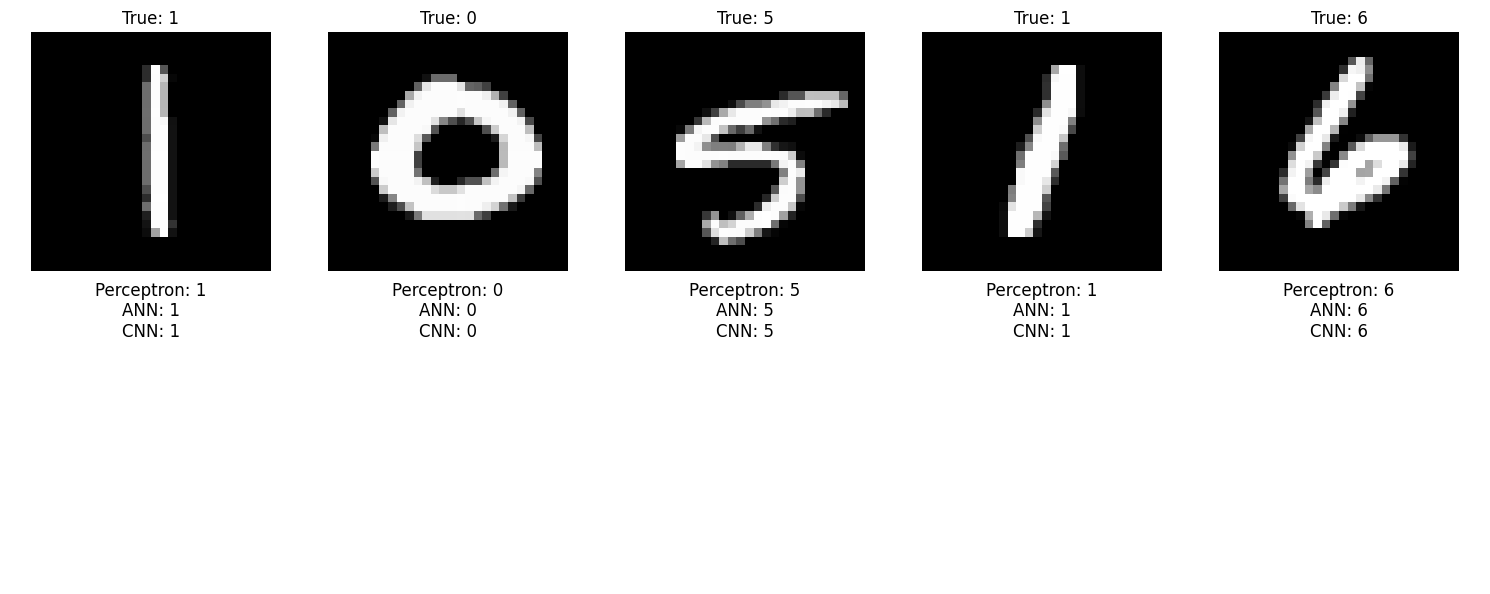

In [86]:
show_side_by_side([perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], X_test_img, X_test_cnn, y_test, 5)

## Confusion Matrices

In [87]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def plot_confusion_matrix(model, X_data, y_true_cat, model_name, is_cnn=False):
    y_pred_probs = model.predict(X_data)
    y_pred_labels = np.argmax(y_pred_probs, axis=1)
    y_true_labels = np.argmax(y_true_cat, axis=1)

    cm = confusion_matrix(y_true_labels, y_pred_labels)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


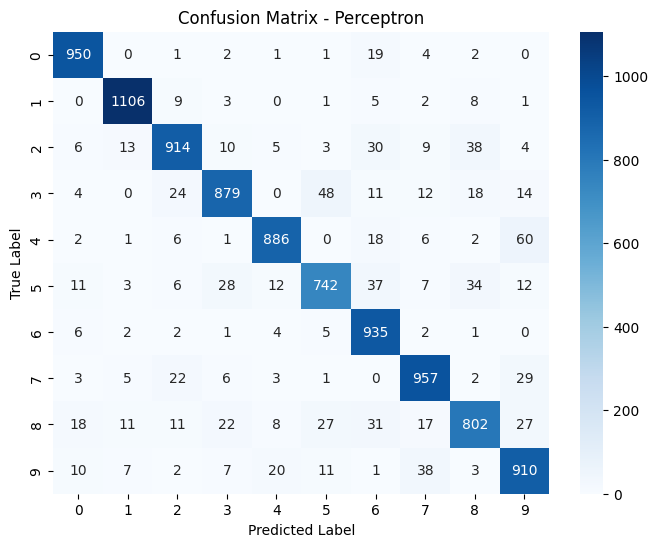

In [88]:
# Plot confusion matrix for Perceptron
plot_confusion_matrix(perceptron, X_test_img, y_test_cat, 'Perceptron')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


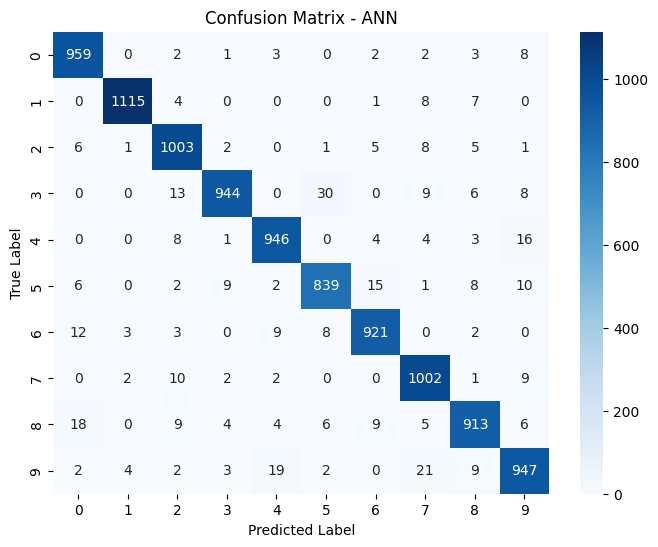

In [89]:
# Plot confusion matrix for ANN
plot_confusion_matrix(ann, X_test_img, y_test_cat, 'ANN')

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


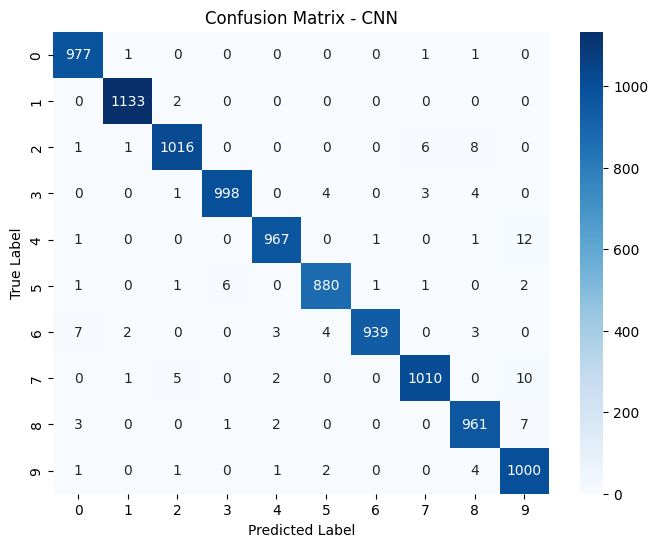

In [90]:
# Plot confusion matrix for CNN
plot_confusion_matrix(cnn, X_test_cnn, y_test_cat, 'CNN', is_cnn=True)

## Final Test Accuracy Comparison

        Model  Validation Accuracy
0  Perceptron               0.9081
1         ANN               0.9589
2         CNN               0.9881


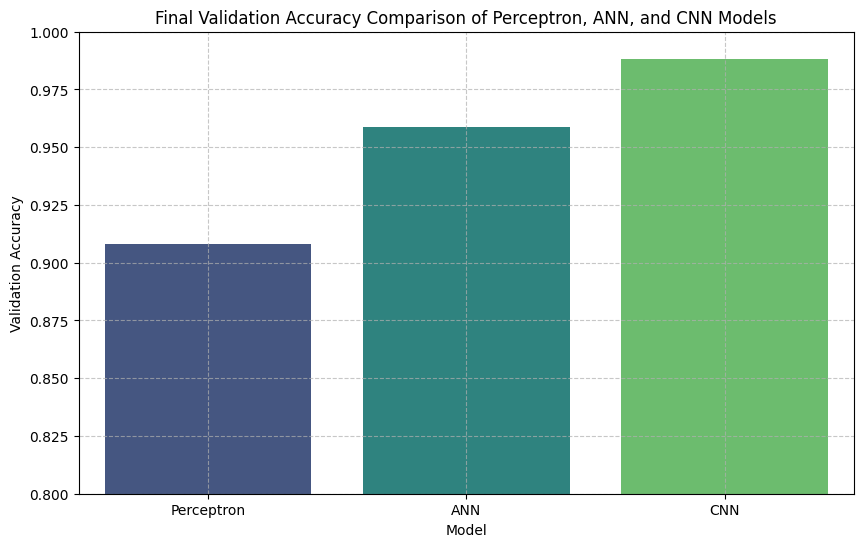

In [91]:
model_accuracies = pd.DataFrame({
    'Model': ['Perceptron', 'ANN', 'CNN'],
    'Validation Accuracy': [acc_perceptron, acc_ann, acc_cnn]
})

print(model_accuracies)

plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='Validation Accuracy', data=model_accuracies, palette='viridis')
plt.title('Final Validation Accuracy Comparison of Perceptron, ANN, and CNN Models')
plt.xlabel('Model')
plt.ylabel('Validation Accuracy')
plt.ylim(0.8, 1.0) # Set y-axis limits to better show differences
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()